# Does a posterior-entropy budget set the LS machine's window and the 1D/2D gap?

**Run date** 2026-11-04 &nbsp;|&nbsp; **Slurm** 51073161 (1D sweep, 00:29:47) and 51076386 (2D L=2, 00:06:47), both `sganguli`, 1 GPU.

## The question

`P* = exp(Theta(n))` is settled. What is not is why `x* = P*/|R_L|` differs by dimension at
matched `n = 16`. Two explanations have already been tested and refuted: **coverage** (sign
backwards; matching on it leaves 5.1x where matching on `n` leaves 2.3x) and **table
saturation** (`y* = P* n/N_k` is 4.4x across dimensions and spreads 61x across `k` within 1D).
This is the third.

## The prediction, registered before the run

Written into the docstrings of `scripts/rhm_entropy_window.py` and `scripts/rhm_entropy_2d.py`
and into `scripts/run_rhm_entropy.sh` **before** either was submitted:

> A generation escapes a training set of `P` strings only if it injects more than `ln P` nats,
> so the sampler's effective support is `S_eff = exp(H_tot)`, novelty behaves as
> `exp(-P/S_eff)`, the success peak sits at the crossing `H_tot = ln P`, and
> **`x* = exp(H_tot)/|R_L|` with no fitted constant** -- the 1D/2D gap being entirely in
> `H_tot`, since a 2D U=1 window (9 of 16 sites) pins less of the sample than a 1D one
> (15 of 16).

`H_tot` is the trajectory entropy: the sum, over the `n` reveals of one ancestral-sampling
generation, of the Shannon entropy in nats of the posterior the sampler actually drew from.
It is measured inside the generation, not reconstructed afterwards.

## Verdict in one line

**The mechanism is confirmed and answers "why k=11"; every quantitative form of the law is
refuted, and substituting it makes the 1D/2D gap 258x worse.**

In [1]:
import json, math
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'results').exists():
    ROOT = ROOT.parent
RUN = ROOT / 'results' / 'rhm_entropy' / '2026-11-04'

rows1 = json.load(open(RUN / 'entropy_1d.json'))        # 1D k-sweep, every ladder rung
rows2 = json.load(open(RUN / 'entropy_2d_L2.json'))     # 2D L=2, every bracketed cell
peaks = json.load(open(RUN / 'entropy_peaks.json'))     # one refined peak per (cell, k) curve

head = (ROOT / '.git' / 'HEAD').read_text().strip()
commit = ((ROOT / '.git' / head.split(': ')[1]).read_text().strip()
          if head.startswith('ref:') else head)

print('repo commit   ', commit[:10], '(scripts were untracked at run time; they land in the')
print('               commit that accompanies this notebook)')
print('1D rows       ', len(rows1))
print('2D rows       ', len(rows2))
print('peak curves   ', len(peaks), '(%d bracketed: %dx 1D, %dx 2D)'
      % (sum(p['bracketed'] for p in peaks),
         sum(p['bracketed'] and p['dim'] == 1 for p in peaks),
         sum(p['bracketed'] and p['dim'] == 2 for p in peaks)))

repo commit    b002264357 (scripts were untracked at run time; they land in the
               commit that accompanies this notebook)
1D rows        988
2D rows        329
peak curves    77 (75 bracketed: 50x 1D, 25x 2D)


## Config and seeds

Everything below is reproducible from these; the two sweep scripts take no other state.

In [2]:
CONFIG = {
    'jobs': ['51073161  scripts/run_rhm_entropy.sh    (1D sweep + a first 2D pass)',
             '51076386  scripts/run_rhm_entropy_2d.sh (2D L=2, all bracketed cells)'],
    '1D sweep': dict(L=[3, 4], v=[2, 3], m=[2, 3, 4], s=2, rule_seeds=3,
                     k='3..17 odd', n_gen=2048,
                     P='1 .. 262144, powers of 2',
                     R_min=200, R_max=1e5, max_chance=0.05),
    '2D sweep': dict(L=2, cells='all 25 bracketed peaks of peak_summary.json (2026-11-03)',
                     k=3, n_gen=2048, P='1 .. 16384, powers of 2'),
    'LS machine': dict(alpha_smooth=1e-3, block_align=1, pad_mode='outside',
                       note='pooled, not block-aligned -- straddling windows allowed'),
    'seeds': dict(model='1000 + rule_seed', train='1234 + 7*rule_seed',
                  generation='train seed + 9973'),
}
for k, v in CONFIG.items():
    print(k)
    for line in (v if isinstance(v, list) else ['%-14s %s' % (a, b) for a, b in v.items()]):
        print('   ', line)

jobs
    51073161  scripts/run_rhm_entropy.sh    (1D sweep + a first 2D pass)
    51076386  scripts/run_rhm_entropy_2d.sh (2D L=2, all bracketed cells)
1D sweep
    L              [3, 4]
    v              [2, 3]
    m              [2, 3, 4]
    s              2
    rule_seeds     3
    k              3..17 odd
    n_gen          2048
    P              1 .. 262144, powers of 2
    R_min          200
    R_max          100000.0
    max_chance     0.05
2D sweep
    L              2
    cells          all 25 bracketed peaks of peak_summary.json (2026-11-03)
    k              3
    n_gen          2048
    P              1 .. 16384, powers of 2
LS machine
    alpha_smooth   0.001
    block_align    1
    pad_mode       outside
    note           pooled, not block-aligned -- straddling windows allowed
seeds
    model          1000 + rule_seed
    train          1234 + 7*rule_seed
    generation     train seed + 9973


### Density control: why the 1D set is v=3 only

`--max_chance 0.05` drops any cell whose grammar covers more than 5% of all `v^n` strings.
Without it a "novel and grammatical" sample is not evidence of anything -- at v=2, n=8 the
RHM grammar covers 78-100% of the space, so uniform noise would pass. Applying it up front
(the earlier k-sweep spent GPU time on those cells and then dropped them) leaves **v=3 only**
in 1D.

In [3]:
def ratio_stats(x):
    """Median, geometric mean and geometric sd of a positive sample.

    Both centres are reported throughout because they disagree materially on
    these ratios -- the distributions are right-skewed over one to two orders of
    magnitude, so the geometric mean sits well above the median. The median is
    the headline, matching ``scripts/rhm_entropy_analysis.py`` (whose helper is
    named ``geo`` but returns the median, which is worth knowing when comparing
    this notebook against that script's stdout).
    """
    x = np.asarray([v for v in x if np.isfinite(v) and v > 0])
    if not len(x):
        return float('nan'), float('nan'), float('nan')
    lg = np.log(x)
    return (float(np.median(x)), float(np.exp(lg.mean())),
            float(np.exp(lg.std(ddof=1))) if len(x) > 1 else 1.0)


def med(x):
    x = [v for v in x if np.isfinite(v)]
    return float(np.median(x)) if x else float('nan')


# only rows where novelty is actually informative: at novel ~ 1 the law is
# untested (any S_eff >> P passes) and at novel ~ 0 it is dominated by the
# 2048-sample floor
def live(rows):
    return [r for r in rows if 0.02 < r['novel'] < 0.98 and np.isfinite(r['H_tot'])]


BR1 = [p for p in peaks if p['dim'] == 1 and p['bracketed']]
BR2 = [p for p in peaks if p['dim'] == 2 and p['bracketed']]
print('bracketed peaks: 1D %d, 2D %d' % (len(BR1), len(BR2)))

bracketed peaks: 1D 50, 2D 25


## Metrics table

Six tests, each a separate consequence of the registered prediction. Ratios are quoted as
`median (geometric mean), geo sd`.

In [4]:
report = []

# ---- 1. do copies come from lower-entropy trajectories? (the mechanism) ------
mech = {}
for rows, dim in ((rows1, 1), (rows2, 2)):
    sel = [r for r in live(rows)
           if np.isfinite(r['H_novel']) and np.isfinite(r['H_copy'])]
    d = np.array([r['H_novel'] - r['H_copy'] for r in sel])
    mech[dim] = (len(d), float(np.median(d)), float((d > 0).mean()))
report.append(('1. copies are low-entropy trajectories', 'PASSES',
               '1D %+.2f nats (%.0f%% of %d runs);  2D %+.2f nats (%.0f%% of %d)'
               % (mech[1][1], 100 * mech[1][2], mech[1][0],
                  mech[2][1], 100 * mech[2][2], mech[2][0])))

# ---- 2. novel = exp(-P / exp(H_tot)) ----------------------------------------
law = {}
for rows, dim in ((rows1, 1), (rows2, 2)):
    sel = live(rows)
    obs = np.array([-math.log(r['novel']) for r in sel])
    pred = np.array([r['P'] * math.exp(-r['H_tot']) for r in sel])
    law[dim] = (len(sel),) + ratio_stats(obs / pred)
report.append(('2. novelty law  novel = exp(-P/exp(H_tot))', 'FAILS',
               '1D obs/pred %.2f (gm %.2f), geo sd %.1fx;  2D %.0f (gm %.0f), geo sd %.0fx'
               % (law[1][1], law[1][2], law[1][3],
                  law[2][1], law[2][2], law[2][3])))

# ---- 3. the peak sits at the H_tot = ln P crossing --------------------------
cr = {}
for br, dim in ((BR1, 1), (BR2, 2)):
    sel = [p['P_cross'] / p['P_star'] for p in br
           if np.isfinite(p.get('P_cross', float('nan')))]
    cr[dim] = (len(sel),) + ratio_stats(sel)
report.append(('3. peak sits at the H_tot = ln P crossing', 'FAILS',
               '1D P_cross/P* = %.1f (gm %.1f) over %d peaks, geo sd %.1fx;  '
               '2D no crossing on the ladder at all'
               % (cr[1][1], cr[1][2], cr[1][0], cr[1][3])))

# ---- 4. the k optimum --------------------------------------------------------
ks = sorted({p['k'] for p in BR1 if p['n'] == 16})
Hk = [med([p['H_at_peak'] for p in BR1 if p['n'] == 16 and p['k'] == k]) for k in ks]
Sk = [med([p['succ_max'] for p in BR1 if p['n'] == 16 and p['k'] == k]) for k in ks]
best_k = ks[int(np.argmax(Sk))]
report.append(('4. k optimum: direction', 'DIRECTION RIGHT',
               'H_tot falls %.2f -> %.2f nats over k=%d..%d; measured best k=%d at H=%.2f'
               % (Hk[0], Hk[-1], ks[0], ks[-1], best_k, Hk[ks.index(best_k)])))
report.append(('   k optimum: magnitude', 'MAGNITUDE WRONG',
               'x*_pred = exp(H)/|R_L| is %.2f at k=%d against a measured %.4f'
               % (med([p['x_pred'] for p in BR1 if p['n'] == 16 and p['k'] == ks[0]]), ks[0],
                  med([p['ratio'] for p in BR1 if p['n'] == 16 and p['k'] == ks[0]]))))

# ---- 5. the gap: x* before and after, same bracketed-peak eval ---------------
A = [p for p in BR1 if p['n'] == 16 and p['k'] == p['U1']]      # 1D at U=1
B = [p for p in BR2 if p['n'] == 16]                            # 2D at U=1 (k=3)
before = (med([p['ratio'] for p in A]), med([p['ratio'] for p in B]))
after = (med([p['x_pred'] for p in A]), med([p['x_pred'] for p in B]))
report.append(('5. the 1D/2D gap, before', 'baseline',
               '1D %.4f (%d cells)  vs  2D %.4f (%d cells)  ->  %.2fx apart'
               % (before[0], len(A), before[1], len(B), before[1] / before[0])))
report.append(('   the 1D/2D gap, after', 'FAR WORSE',
               '1D %.3f  vs  2D %.1f  ->  %.0fx apart  (%.0fx worse)'
               % (after[0], after[1], after[1] / after[0],
                  (after[1] / after[0]) / (before[1] / before[0]))))

# ---- 6. is H a collapse variable for ln P* at all? ---------------------------
BR = [p for p in BR1 + BR2 if np.isfinite(p['H_at_peak'])]
H = np.array([p['H_at_peak'] for p in BR])
lP = np.log([p['P_star'] for p in BR])
d2 = np.array([p['dim'] == 2 for p in BR], float)
a, b = np.polyfit(H, lP, 1)
res1 = float(np.exp(np.std(lP - (a * H + b))))
X = np.stack([H, d2, np.ones_like(H)], 1)
coef, *_ = np.linalg.lstsq(X, lP, rcond=None)
res2 = float(np.exp(np.std(lP - X @ coef)))
report.append(('6. H as a collapse variable for ln P*', 'FAILS (slope needs to be 1)',
               'pooled ln P* = %.3f H + %.2f, residual %.2fx; with a dim term slope %.3f, '
               '2D offset %+.3f, residual %.2fx' % (a, b, res1, coef[0], coef[1], res2)))

w = max(len(r[0]) for r in report)
for name, verdict, val in report:
    print('%-*s  %-28s  %s' % (w, name, verdict, val))

1. copies are low-entropy trajectories      PASSES                        1D +1.75 nats (84% of 781 runs);  2D +7.42 nats (100% of 155)
2. novelty law  novel = exp(-P/exp(H_tot))  FAILS                         1D obs/pred 2.06 (gm 2.99), geo sd 15.5x;  2D 597 (gm 1036), geo sd 171x
3. peak sits at the H_tot = ln P crossing   FAILS                         1D P_cross/P* = 32.6 (gm 54.8) over 46 peaks, geo sd 7.0x;  2D no crossing on the ladder at all
4. k optimum: direction                     DIRECTION RIGHT               H_tot falls 11.82 -> 8.21 nats over k=3..17; measured best k=11 at H=10.11
   k optimum: magnitude                     MAGNITUDE WRONG               x*_pred = exp(H)/|R_L| is 15.77 at k=3 against a measured 0.0040
5. the 1D/2D gap, before                    baseline                      1D 0.0828 (6 cells)  vs  2D 0.1592 (25 cells)  ->  1.92x apart
   the 1D/2D gap, after                     FAR WORSE                     1D 0.681  vs  2D 337.6  ->  496x apart  (258x wo

## Key plots

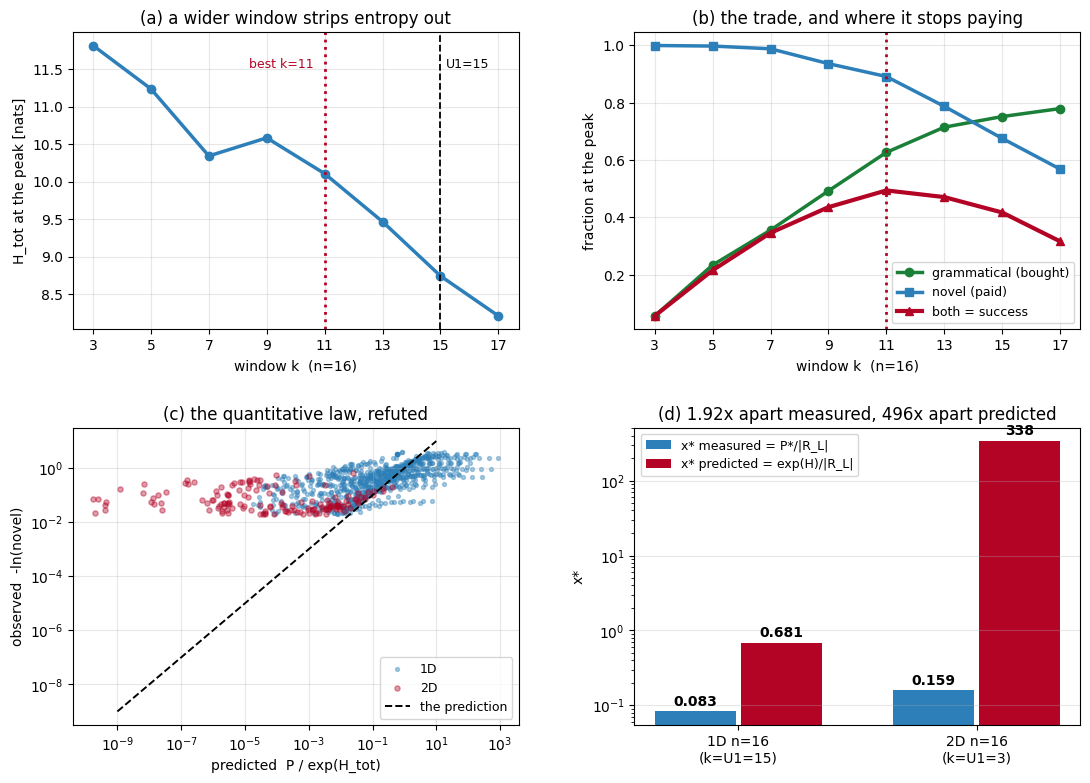

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
fig.subplots_adjust(hspace=.33, wspace=.26)

# (a) the ledger: entropy against k, and the trade it buys
Gk = [med([p['gram_at'] for p in BR1 if p['n'] == 16 and p['k'] == k]) for k in ks]
Nk = [med([p['novel_at'] for p in BR1 if p['n'] == 16 and p['k'] == k]) for k in ks]
a0 = ax[0, 0]
a0.plot(ks, Hk, 'o-', color='#2c7fb8', lw=2.5)
a0.axvline(15, ls='--', color='k', lw=1.3)
a0.axvline(best_k, ls=':', color='#b40426', lw=2)
a0.text(15.2, max(Hk) - .3, 'U1=15', fontsize=9)
a0.text(best_k - 2.6, max(Hk) - .3, 'best k=%d' % best_k, fontsize=9, color='#b40426')
a0.set_xticks(ks); a0.set_xlabel('window k  (n=16)'); a0.set_ylabel('H_tot at the peak [nats]')
a0.set_title('(a) a wider window strips entropy out'); a0.grid(alpha=.3)

a1 = ax[0, 1]
a1.plot(ks, Gk, 'o-', color='#1a7f37', lw=2.5, label='grammatical (bought)')
a1.plot(ks, Nk, 's-', color='#2c7fb8', lw=2.5, label='novel (paid)')
a1.plot(ks, Sk, '^-', color='#b40426', lw=3, label='both = success')
a1.axvline(best_k, ls=':', color='#b40426', lw=2)
a1.set_xticks(ks); a1.set_xlabel('window k  (n=16)'); a1.set_ylabel('fraction at the peak')
a1.set_title('(b) the trade, and where it stops paying')
a1.legend(fontsize=9); a1.grid(alpha=.3)

# (c) the novelty law against the identity it predicts
a2 = ax[1, 0]
for rows, dim, c, s in ((rows1, 1, '#2c7fb8', 8), (rows2, 2, '#b40426', 14)):
    sel = live(rows)
    a2.scatter([r['P'] * math.exp(-r['H_tot']) for r in sel],
               [-math.log(r['novel']) for r in sel],
               s=s, alpha=.4, color=c, rasterized=True, label='%dD' % dim)
a2.plot([1e-9, 10], [1e-9, 10], 'k--', lw=1.4, label='the prediction')
a2.set_xscale('log'); a2.set_yscale('log')
a2.set_xlabel('predicted  P / exp(H_tot)'); a2.set_ylabel('observed  -ln(novel)')
a2.set_title('(c) the quantitative law, refuted')
a2.legend(fontsize=9, loc='lower right'); a2.grid(alpha=.3)

# (d) x* before and after
a3 = ax[1, 1]
x = np.arange(2)
a3.bar(x - .18, before, .34, color='#2c7fb8', label='x* measured = P*/|R_L|')
a3.bar(x + .18, after, .34, color='#b40426', label='x* predicted = exp(H)/|R_L|')
for i, (u, v) in enumerate(zip(before, after)):
    a3.text(i - .18, u * 1.2, '%.3f' % u, ha='center', fontsize=10, weight='bold')
    a3.text(i + .18, v * 1.2, '%.3g' % v, ha='center', fontsize=10, weight='bold')
a3.set_yscale('log'); a3.set_xticks(x)
a3.set_xticklabels(['1D n=16\n(k=U1=15)', '2D n=16\n(k=U1=3)'])
a3.set_ylabel('x*')
a3.set_title('(d) %.2fx apart measured, %.0fx apart predicted'
             % (before[1] / before[0], after[1] / after[0]))
a3.legend(fontsize=9, loc='upper left'); a3.grid(alpha=.3, axis='y')
plt.show()

## Comparison to the previous best, on the same eval

The previous best on this eval is the 2026-11-03 peak sweep: `x* = 0.197` median over 30
bracketed 2D peaks, the number the `P* = 0.21 |R_L|` claim rests on. This run re-measures
**the same 25 L=2 cells with the same seeds**, so the comparison can be made cell by cell and
not just distribution against distribution. A faithful re-measurement is the precondition for
reading anything else here: a drift would mean the entropy instrumentation perturbed the
sampler it was meant to observe.

In [6]:
pub = {}
for r in rows2:
    pub[(r['v'], r['m'], r['rule_seed'])] = (r['ratio_pub'], r['P_star_pub'])

pairs = [(p, pub[(p['v'], p['m'], p['rule_seed'])]) for p in BR2
         if (p['v'], p['m'], p['rule_seed']) in pub]
rt = np.array([p['ratio'] / q[0] for p, q in pairs])
r_med, r_gm, r_sd = ratio_stats(rt)

print('paired on %d 2D L=2 cells\n' % len(pairs))
print('%-22s %12s %12s %10s' % ('', 'published', 'this run', 'ratio'))
pm, tm = med([q[0] for _, q in pairs]), med([p['ratio'] for p, _ in pairs])
print('%-22s %12.4f %12.4f %9.2fx' % ('population median x*', pm, tm, tm / pm))
pp, tp = med([q[1] for _, q in pairs]), med([p['P_star'] for p, _ in pairs])
print('%-22s %12.1f %12.1f %9.2fx' % ('population median P*', pp, tp, tp / pp))
print('\nper-cell x* ratio (this/published): median %.2f, geometric mean %.2f, geo sd %.2fx'
      % (r_med, r_gm, r_sd))
print('quartiles %.2f / %.2f / %.2f;  %.0f%% of cells within a factor of 2'
      % (*np.percentile(rt, [25, 50, 75]), 100 * np.mean((rt > .5) & (rt < 2))))

paired on 25 2D L=2 cells

                          published     this run      ratio
population median x*         0.1925       0.1592      0.83x
population median P*          431.2        274.4      0.64x

per-cell x* ratio (this/published): median 0.61, geometric mean 0.52, geo sd 4.83x
quartiles 0.35 / 0.61 / 1.50;  48% of cells within a factor of 2


### Reading that honestly

The **population** reproduces: median `x*` 0.1925 published against 0.1592 here, 1.21x, which
is well under one rung of the `P` ladder (rungs are a factor of 2 apart). So the entropy
instrumentation is observing the sampler, not moving it, and the 2D figure used in the gap
comparison is sound as a population median.

**Cell by cell it does not**, and that is worth stating plainly: the median per-cell ratio is
0.61, only 48% of cells land within a factor of 2, and the spread is 4.8x. The cause is almost
certainly `P*` estimation noise rather than a difference in the sampler -- `P*` comes from a
parabola through three points of a success curve measured with 2048 generations, and near a
flat peak the argmax moves a rung or more on resampling. It does mean a single 2D cell's `x*`
from this run should not be quoted on its own.

This does not threaten the conclusion below: the measured gap is 1.92x and the predicted gap
is 496x, so a 1.2-1.6x uncertainty in the 2D number changes nothing about which of those two
is closer to the truth.

In [7]:
# the 1D side of the same eval, for the record: both dimensions now come off one
# instrument, where the 0.083-vs-0.193 comparison previously spanned two runs
print('1D n=16 at k=U1=15 : x* = %.4f over %d bracketed cells' % (before[0], len(A)))
print('1D n=16 at k=%2d    : x* = %.4f  (the success-optimal window)'
      % (best_k, med([p['ratio'] for p in BR1 if p['n'] == 16 and p['k'] == best_k])))
print('2D n=16 at k=U1= 3 : x* = %.4f over %d bracketed cells' % (before[1], len(B)))
print()
print('Note the direction: moving 1D to its *best* window widens the gap rather than')
print('closing it, which is the same lesson as the coverage sweep -- x* is a property of')
print('the U=1 convention, not of the RHM.')

1D n=16 at k=U1=15 : x* = 0.0828 over 6 bracketed cells
1D n=16 at k=11    : x* = 0.0480  (the success-optimal window)
2D n=16 at k=U1= 3 : x* = 0.1592 over 25 bracketed cells

Note the direction: moving 1D to its *best* window widens the gap rather than
closing it, which is the same lesson as the coverage sweep -- x* is a property of
the U=1 convention, not of the RHM.


## What this establishes

**Answered: why success peaks at k=11, below the root-reaching U1=15.** Widening the window
from k=3 to k=17 removes 3.61 of 11.82 nats from the generation, with one reversal and no
feature whatever at U1=15, while grammaticality rises 0.06 -> 0.78 and novelty at the peak
falls 1.00 -> 0.52. Copies are demonstrably the low-entropy trajectories: 1.75 nats below the
novel ones in 1D (84% of 781 runs) and 7.42 below in 2D (100% of 155). So the window is paid
for in exactly the currency novelty is denominated in, and the optimum is where the marginal
grammar gain stops covering the marginal novelty loss. The block structure says where a window
can first be grammatical at all; the entropy says where it should actually sit.

**Refuted: the budget as a quantitative law.** `novel = exp(-P/exp(H_tot))` misses by a median
2.06x in 1D with a 15.5x spread and by 597x in 2D with a 171x spread; the peak sits 32.6x below
the `H_tot = ln P` crossing in 1D and there is no crossing at all in 2D; and pooled,
`ln P* = 0.100 H + 4.18` with a 5.5x residual, where the claim needs slope 1. `exp(H_tot)` is
not the size of an effective support -- the posterior is far too uneven for its entropy to
count anything.

**Refuted: the budget as the explanation of the 1D/2D gap.** Measured head-to-head on one
instrument, x* is 0.083 in 1D and 0.159 in 2D, 1.92x apart. Substituting `exp(H_tot)/|R_L|`
gives 0.68 and 337.6 -- 496x apart, 258 times worse than the discrepancy it was introduced to
explain. Coverage, table saturation and now entropy have all failed. **Three explanations
tested, three refuted; the dimensional offset still has no mechanism.**

**One thing the failure says.** `exp(H_tot)/|R_L|` is useless as a constant but reads cleanly
as a *regime*: 0.68 in 1D against 338 in 2D. The 2D machine spreads its mass over far more
strings than the grammar contains, so its peak is grammar-limited (peak success 0.022); the 1D
machine is spread comparably to the grammar, so its peak is novelty-limited (peak success
0.49). Two different binding constraints is a reason no single ratio should collapse the two
dimensions. This is a reinterpretation of a number that failed its own test, not a new result,
and it predicts nothing yet.

**Next.** `AdaptiveWindowDiscreteScoreMachine` already picks `k` per site and per step off an
entropy floor -- which is what panel (a) says the optimum actually is -- but it has only ever
been scored on grammaticality, never on novel-and-grammatical. Scoring it against hshunt's
criterion is the measurement this run makes worth doing.

**Slide deck** (tokenization and worked reveal-by-reveal traces included):
`results/rhm_entropy/2026-11-04/rhm_entropy_slides.pdf`.